import numpy as np
import matplotlib.pyplot as plt

In [69]:
N_max = 10
E_j = np.array([1,5,15,30,50])  # Example values for E_j
E_c = 1 
H_list = [] #list of H-matrices  for every E_j
n_vals=np.arange(-N_max, N_max + 1)  # n values from -N_max to N_max
N=2*N_max+1
for E in E_j:
    H = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            n, m = n_vals[i], n_vals[j]     
            if n == m:
                H[i, j] = 4 * E_c * n**2
            elif abs(n - m) == 1:
                H[i, j] = -E / 2
    H_list.append(H)

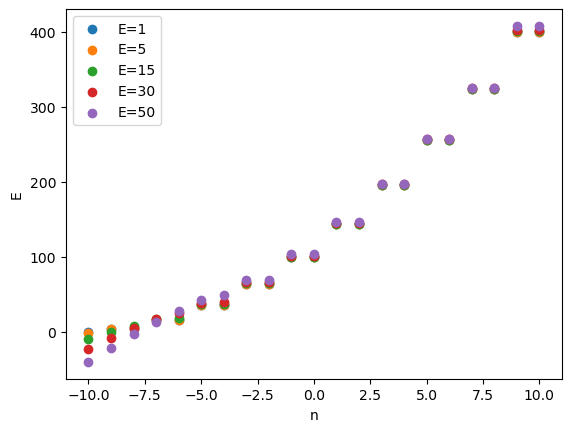

In [70]:
for i, E in enumerate(E_j):
    H = H_list[i]
    eigenvalues, eigenvectors = np.linalg.eigh(H)
    plt.scatter(n_vals, eigenvalues, label=f'E={E}')
plt.xlabel('n')
plt.ylabel('E')
plt.legend()
plt.show()

In [71]:
vals, vecs = np.linalg.eigh(H_list[1])  # E_j = 5

E_g, E_e = vals[0], vals[1]
psi_g, psi_e = vecs[:, 0], vecs[:, 1]   # BEMÆRK: kolonner, ikke rækker

print(f"E_g = {E_g:.6f}")
print(f"E_e = {E_e:.6f}")
print(f"Omega = {E_e - E_g:.6f}")

E_g = -2.153078
E_e = 3.492474
Omega = 5.645553


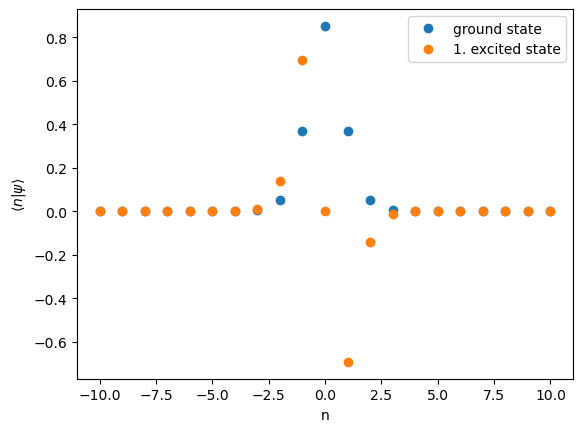

In [72]:
plt.plot(n_vals, psi_g, 'o', label='ground state')
plt.plot(n_vals, psi_e, 'o', label='1. excited state')
plt.xlabel('n'); plt.ylabel(r'$\langle n | \psi \rangle$')
plt.legend()

In [73]:
vals, vecs = np.linalg.eigh(H_list[1])  # E_j = 5
E_g, E_e = vals[0], vals[1]
psi_g, psi_e = vecs[:, 0], vecs[:, 1]   # BEMÆRK: kolonner, ikke rækker
n_op = np.diag(n_vals)
n_q=np.zeros((2,2))
psi=np.array([psi_g, psi_e])
for i in range(2):
    for j in range(2):
        n_q[i,j] = psi[i].conj().T @ n_op @ psi[j]  #@ is just matrix multiplication
#rounding to 3 decimals
print(np.round(n_q,3))

[[-0.    -0.537]
 [-0.537 -0.   ]]


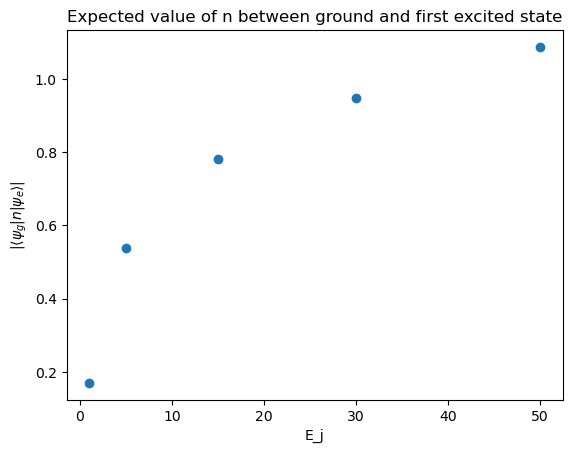

In [76]:
overlaps = []
for i, E in enumerate(E_j):
    H = H_list[i]
    vals, vecs = np.linalg.eigh(H)
    psi_g, psi_e = vecs[:, 0], vecs[:, 1]
    n_op = np.diag(n_vals)
    overlap = psi_g.conj().T @ n_op @ psi_e
    overlaps.append(overlap)
plt.plot(E_j, np.abs(overlaps), 'o')
plt.xlabel('E_j')
plt.ylabel(r'$|\langle \psi_g | n | \psi_e \rangle|$')
plt.title('Expected value of n between ground and first excited state')
plt.show()